# Part 3: Ranking and Filtering

This notebook contains all the code and results of Part 3. The pre-processing of Part 1 (`../part_1/preprocessing.py`) and the
inverted index, the conjunctive retrieval and the evaluation metrics of Part 2 (`../part_2/indexing.py`, `evaluation.py`,
`judgments.py`) are imported. The new code is in this folder:

| Module | Content |
|---|---|
| `ranking.py` | our own score (`CustomRanker`), word2vec + cosine (`Word2VecRanker`), doc2vec (`Doc2VecRanker`, only for the comparison of section 6), and `build_engines`, which returns one search engine per ranking method |
| `search.py` | command-line search: `python search.py "men denim jacket" --method bm25 --top 20` |
| `test_part3.py` | tests of the new rankers against direct implementations of their formulas |

Structure:
1. Setup and loading
2. The retrieval pipeline (query → AND → ranking)
3. TF-IDF + cosine vs BM25
4. Our score
5. word2vec + cosine: top-20 lists of the five queries of Part 2
6. Better representations than the average of word2vec vectors
7. Summary

## 1. Setup and loading

In [9]:
import os, sys, re, time, json, math, warnings
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import nltk
from scipy.stats import kendalltau

warnings.filterwarnings("ignore")

# the notebook lives in project_progress/part_3, the repo root is two levels up
ROOT = os.path.abspath(os.path.join(os.getcwd(), "..", ".."))
PART1 = os.path.join(ROOT, "project_progress", "part_1")
PART2 = os.path.join(ROOT, "project_progress", "part_2")
for path in (os.getcwd(), PART1, PART2):
    if path not in sys.path:
        sys.path.insert(0, path)
DATA_PATH = os.path.join(ROOT, "data", "fashion_products_dataset.json")
LABELS_PATH = os.path.join(ROOT, "data", "validation_labels.csv")
CORPUS_PATH = os.path.join(ROOT, "data", "processed_corpus.pkl")   # written by the Part 1 notebook
FIG_DIR = os.path.join(os.getcwd(), "figures")
RES_DIR = os.path.join(os.getcwd(), "results")
W2V_PATH = os.path.join(os.getcwd(), "models", "word2vec_fashion.bin")
os.makedirs(FIG_DIR, exist_ok=True)
os.makedirs(RES_DIR, exist_ok=True)

try:
    nltk.corpus.stopwords.words("english")
except LookupError:
    nltk.download("stopwords", quiet=True)

import preprocessing as pp                                                    # Part 1
from indexing import InvertedIndex, TfidfRanker, Bm25Ranker, SearchEngine     # Part 2 
from evaluation import condense, evaluate_run                                 # Part 2
import judgments as J                                                         # Part 2
import ranking as rk                                                          # Part 3

sns.set_theme(style="whitegrid")
pd.set_option("display.width", 250)
pd.set_option("display.max_colwidth", 70)
pd.set_option("display.max_columns", 40)

METHODS = list(rk.METHODS)                                    # tfidf, bm25, custom, word2vec
NAMES = rk.METHOD_NAMES
COLORS = {"tfidf": "#2a78d6", "bm25": "#eb6834", "custom": "#1baf7a", "word2vec": "#eda100"}
MARKERS = {"tfidf": "o", "bm25": "s", "custom": "^", "word2vec": "D"}

def savefig(name):
    plt.tight_layout()
    plt.savefig(os.path.join(FIG_DIR, f"{name}.png"), dpi=150, bbox_inches="tight")
    plt.show()

In [10]:
if os.path.exists(CORPUS_PATH):
    corpus = pd.read_pickle(CORPUS_PATH)             # Part 1 output
else:
    corpus = pp.preprocess_corpus(pd.read_json(DATA_PATH))
    corpus.to_pickle(CORPUS_PATH)
labels = pd.read_csv(LABELS_PATH)

index = InvertedIndex(corpus.pid.tolist(), corpus.all_terms.tolist())     # same index as Part 2 (merged field `all_terms`)
doc_len = np.array(index.doc_length)
pid_pos = {pid: i for i, pid in enumerate(index.pids)}
print("documents:", index.num_docs, "| vocabulary:", index.vocabulary_size, "| average document length: %.1f terms" % doc_len.mean())
assert index.num_docs == 28080 and index.vocabulary_size == 5865       # same figures as Parts 1 and 2

documents: 28080 | vocabulary: 5865 | average document length: 44.7 terms


**Queries and relevance judgments.** We use the same seven queries as in Part 2: the two validation queries of the statement
(Q1, Q2, judged in `validation_labels.csv`) and our five test queries (T1..T5). The judgments of T1..T5 are produced by the
guidelines of `judgments.py` (Part 2), applied to every document of the collection. The evaluation protocol is also the one of
Part 2: for Q1 and Q2 the ranking is reduced to the judged documents (condensed list), for T1..T5 the whole ranking is evaluated.

In [11]:
VALIDATION_QUERIES = {"Q1": "women full sleeve sweatshirt cotton", "Q2": "men slim jeans blue"}
TEST_QUERIES = {f"T{qid}": text for qid, text in J.QUERIES.items()}
QUERIES = {**VALIDATION_QUERIES, **TEST_QUERIES}
KS = (5, 10, 20)

qrels = {f"Q{q}": dict(zip(g.pid, g.labels)) for q, g in labels.groupby("query_id")}
records = corpus.to_dict(orient="records")
for qid in J.QUERIES:
    qrels[f"T{qid}"] = {r["pid"]: 1 for r in records if J.judge(qid, r)[0] == 1}        # relevant documents of the collection
relevant = {q: {pid for pid, lab in qrels[q].items() if lab > 0} for q in QUERIES}
assert [len(relevant[q]) for q in TEST_QUERIES] == [79, 43, 48, 74, 38]                 # same R as in the Part 2 report

query_table = pd.DataFrame([{"id": q, "query": text, "terms after pre-processing": " ".join(pp.preprocess_text(text)),
                             "AND matches": len(index.conjunctive(pp.preprocess_text(text))),
                             "judged": len(qrels[q]) if q in VALIDATION_QUERIES else index.num_docs,
                             "relevant (R)": len(relevant[q])} for q, text in QUERIES.items()]).set_index("id")
query_table.to_csv(os.path.join(RES_DIR, "queries.csv"))
query_table

,query,terms after pre-processing,AND matches,judged,relevant (R)
id,,,,,
Q1,women full sleeve sweatshirt cotton,women full sleev sweatshirt cotton,496,20,13
Q2,men slim jeans blue,men slim jean blue,224,20,10
T1,men black track pants polyester,men black track pant polyest,79,28080,79
T2,women black v neck tshirt,women black neck tshirt,1584,28080,43
T3,men grey hooded sweatshirt,men grey hood sweatshirt,40,28080,48
T4,women striped shirt,women stripe shirt,114,28080,74
T5,men denim jacket,men denim jacket,73,28080,38


## 2. The retrieval pipeline

Every search follows the same three steps, and only the last one changes between methods:

1. the query is pre-processed with `preprocess_text` (Part 1), like the documents;
2. the inverted index returns the documents that contain all the query terms (conjunctive query, Part 2);
3. the matching documents are sorted by one of the four scores.

`rk.build_engines` creates one `SearchEngine` (Part 2 class) per method. The word vectors of section 5 are read from
`models/word2vec_fashion.bin`.

In [12]:
t0 = time.time()
w2v_was_stored = os.path.exists(W2V_PATH)
engines = rk.build_engines(corpus, pp.preprocess_text, W2V_PATH, index=index)
print("word vectors:", "loaded from" if w2v_was_stored else "trained and saved to", os.path.relpath(W2V_PATH),
      "| engines ready in %.1f s:" % (time.time() - t0), list(engines))

# whole AND ranking of every query with every method
results = {m: {q: engines[m].search(text) for q, text in QUERIES.items()} for m in METHODS}
runs = {m: {q: [pid for pid, _ in results[m][q]] for q in QUERIES} for m in METHODS}

# the four methods return exactly the documents of the AND, only the order changes
for q, text in QUERIES.items():
    and_set = {index.pids[d] for d in index.conjunctive(pp.preprocess_text(text))}
    assert all(set(runs[m][q]) == and_set for m in METHODS)
print("the four methods return the same documents for the 7 queries (the AND result); only the order changes")

def show(method, text, k=5):
    rows = [{"rank": i, "score": round(s, 3), "pid": pid, "title": corpus.loc[pid, "title"], "brand": corpus.loc[pid, "brand"],
             "price": corpus.loc[pid, "selling_price"], "rating": corpus.loc[pid, "average_rating"],
             "discount": corpus.loc[pid, "discount"], "out of stock": corpus.loc[pid, "out_of_stock"]}
            for i, (pid, s) in enumerate(engines[method].search(text, top_k=k), 1)]
    return pd.DataFrame(rows)

for m in METHODS:
    print(f"{NAMES[m]}: top 3 of {TEST_QUERIES['T5']!r}")
    display(show(m, TEST_QUERIES["T5"], 3))

word vectors: loaded from models\word2vec_fashion.bin | engines ready in 2.4 s: ['tfidf', 'bm25', 'custom', 'word2vec']
the four methods return the same documents for the 7 queries (the AND result); only the order changes
TF-IDF + cosine: top 3 of 'men denim jacket'


,rank,score,pid,title,brand,price,rating,discount,out of stock
0,1,0.915,JCKFZZN6AWQZ8FC2,Full Sleeve Solid Men Denim Jacket,None,1249.0,NaN,53.0,False
1,2,0.826,JCKFWC5ZAF3BRTPA,Full Sleeve Solid Men Denim Jacket,VOXA,1199.0,3.7,53.0,True
2,3,0.793,JCKFVDPW4WNPBGS2,Full Sleeve Solid Men Denim Jacket,VOXA,1199.0,3.7,53.0,False


BM25: top 3 of 'men denim jacket'


,rank,score,pid,title,brand,price,rating,discount,out of stock
0,1,17.028,JCKFZZN6AWQZ8FC2,Full Sleeve Solid Men Denim Jacket,None,1249.0,NaN,53.0,False
1,2,16.946,JCKFURYWGYKVKFH3,Full Sleeve Solid Men Denim Jacket,VOXA,1199.0,3.7,53.0,True
2,3,16.933,JCKFWC5ZHSAEVYMS,Full Sleeve Solid Men Denim Jacket,VOXA,1199.0,3.7,53.0,True


Our score: top 3 of 'men denim jacket'


,rank,score,pid,title,brand,price,rating,discount,out of stock
0,1,50.344,JCKFWC5YZKFWXGEB,Full Sleeve Solid Men Denim Jacket,VOXA,1199.0,4.0,53.0,False
1,2,49.754,JCKFZZN6AWQZ8FC2,Full Sleeve Solid Men Denim Jacket,None,1249.0,NaN,53.0,False
2,3,49.091,JCKFVDPW4WNPBGS2,Full Sleeve Solid Men Denim Jacket,VOXA,1199.0,3.7,53.0,False


word2vec + cosine: top 3 of 'men denim jacket'


,rank,score,pid,title,brand,price,rating,discount,out of stock
0,1,0.836,JCKFMHKMYEWHQFNU,Full Sleeve Printed Men Denim Casual Jacket,Solid Styl,1424.0,3.3,71.0,True
1,2,0.814,JCKFKKFZ7QB2KUQV,Full Sleeve Washed Men Denim Jacket,Solid Styl,1443.0,3.8,63.0,False
2,3,0.811,JCKFKKFZMDEHEZQS,Full Sleeve Washed Men Denim Jacket,Solid Styl,1424.0,2.4,64.0,True


**Tests.** `test_part3.py` checks our score and word2vec + cosine against direct implementations of their formulas, BM25
against a value computed by hand, the reproducibility of the training and the AND semantics of every engine.

In [13]:
import test_part3 as T
for name in sorted(n for n in dir(T) if n.startswith("test_")):
    getattr(T, name)()
    print("ok", name)

ok test_all_methods_rank_the_same_and_set
ok test_bm25_hand_computed
ok test_custom_score_equals_formula
ok test_custom_score_factors
ok test_custom_score_without_weights_is_bm25
ok test_remove_first_component
ok test_text_vector_is_the_average
ok test_training_is_reproducible
ok test_word2vec_cosine_brute_force


In [14]:
def evaluate(run):
    # run = {query id: ranking (pids)}. Validation queries: condensed list; test queries: whole ranking (protocol of Part 2).
    val = {q: condense(run[q], qrels[q]) for q in VALIDATION_QUERIES}
    test = {q: run[q] for q in TEST_QUERIES}
    tv = evaluate_run(val, {q: qrels[q] for q in VALIDATION_QUERIES}, KS)
    tt = evaluate_run(test, {q: qrels[q] for q in TEST_QUERIES}, KS)
    row = {"val MAP": tv.loc["mean", "AP"], "val NDCG@10": tv.loc["mean", "NDCG@10"],
           "test MAP": tt.loc["mean", "AP"], "test P@10": tt.loc["mean", "P@10"], "test P@20": tt.loc["mean", "P@20"],
           "test NDCG@10": tt.loc["mean", "NDCG@10"], "test NDCG@20": tt.loc["mean", "NDCG@20"],
           "test MRR": tt.loc["mean", "RR"]}
    row.update({f"AP {q}": tv.loc[q, "AP"] for q in VALIDATION_QUERIES})
    row.update({f"AP {q}": tt.loc[q, "AP"] for q in TEST_QUERIES})
    return row

def run_ranker(ranker):
    eng = SearchEngine(index, pp.preprocess_text, ranker)
    return {q: [pid for pid, _ in eng.search(text)] for q, text in QUERIES.items()}

MAIN_COLS = ["val MAP", "val NDCG@10", "test MAP", "test P@10", "test P@20", "test NDCG@10"]
AP_COLS = [f"AP {q}" for q in QUERIES]
comparison = pd.DataFrame({NAMES[m]: evaluate(runs[m]) for m in METHODS}).T
comparison.round(3).to_csv(os.path.join(RES_DIR, "method_comparison.csv"))

# every metric of every query and method (same protocol), and the number of different score values in each ranking
rows = []
for m in METHODS:
    for q in QUERIES:
        ranking = condense(runs[m][q], qrels[q]) if q in VALIDATION_QUERIES else runs[m][q]
        metrics = evaluate_run({q: ranking}, {q: qrels[q]}, KS).loc[q]
        scores = [s for _, s in results[m][q]]
        rows.append({"method": NAMES[m], "query": q, **metrics.to_dict(), "AND matches": len(scores),
                     "distinct scores": len({round(s, 9) for s in scores}), "best score": max(scores), "lowest score": min(scores)})
per_query = pd.DataFrame(rows)
per_query.round(4).to_csv(os.path.join(RES_DIR, "per_query_metrics.csv"), index=False)

# 3. TF-IDF + cosine vs BM25

Both are implemented in `../part_2/indexing.py` (`TfidfRanker`, `Bm25Ranker`).

**TF-IDF + cosine** (vector space model):

$$w_{t,d} = (1 + \log_2 tf_{t,d}) \cdot \log_2\frac{N}{df_t}, \qquad
\text{score}(q,d) = \frac{\sum_{t \in q} w_{t,q}\, w_{t,d}}{\lVert q \rVert \; \lVert d \rVert}$$

**BM25** ($k_1 = 1.2$, $b = 0.75$, $avgdl$ = average document length):

$$\text{score}(q,d) = \sum_{t \in q} \log_2\!\Big(1 + \frac{N - df_t + 0.5}{df_t + 0.5}\Big) \cdot
\frac{tf_{t,d}\,(k_1 + 1)}{tf_{t,d} + k_1\,\big(1 - b + b\,\frac{|d|}{avgdl}\big)}$$

The two differ in three things: how the score grows with the term frequency, how the length of the document is taken into
account, and what the score depends on besides the query terms (in the cosine, the norm $\lVert d \rVert$ includes every
term of the document).

## 3.1 The same query with both rankings

In [15]:
def side_by_side(q, a="tfidf", b="bm25", k=10):
    terms = list(dict.fromkeys(pp.preprocess_text(QUERIES[q])))
    def block(m):
        rows = []
        for pid, s in results[m][q][:k]:
            d = pid_pos[pid]
            tfs = [dict(index.get_postings(t)).get(d, 0) for t in terms]
            rows.append({"title": corpus.loc[pid, "title"][:42], "len": doc_len[d], "tf": " ".join(map(str, tfs)),
                         "score": round(s, 3), "rel": int(pid in relevant[q])})
        return pd.DataFrame(rows, index=range(1, len(rows) + 1))
    out = pd.concat({NAMES[a]: block(a), NAMES[b]: block(b)}, axis=1)
    out.index.name = "rank"
    return out

# len = document length in terms; tf = term frequency of each query term in the document; rel = our judgment
print("T5:", QUERIES["T5"], "| query terms:", pp.preprocess_text(QUERIES["T5"]))
display(side_by_side("T5"))
print("Q1:", QUERIES["Q1"], "| query terms:", pp.preprocess_text(QUERIES["Q1"]))
display(side_by_side("Q1"))

T5: men denim jacket | query terms: ['men', 'denim', 'jacket']


TF-IDF + cosine                                                       BM25                       
                                    title len     tf  score rel                                title len     tf   score rel
rank                                                                                                                       
1      Full Sleeve Solid Men Denim Jacket  20  2 3 3  0.915   1   Full Sleeve Solid Men Denim Jacket  20  2 3 3  17.028   1
2      Full Sleeve Solid Men Denim Jacket  22  2 3 3  0.826   1   Full Sleeve Solid Men Denim Jacket  27  3 4 3  16.946   1
3      Full Sleeve Solid Men Denim Jacket  28  2 4 3  0.793   1   Full Sleeve Solid Men Denim Jacket  21  2 3 3  16.933   1
4      Full Sleeve Solid Men Denim Jacket  28  2 4 3  0.792   1  Full Sleeve Washed Men Denim Jacket  21  2 3 3  16.933   1
5      Full Sleeve Solid Men Denim Jacket  27  3 4 3  0.786   1  Full Sleeve Washed Men Denim Jacket  21  2 3 3  16.933   1
6     Full Sleeve Washed Men Denim Jacket  21  2 3 3  0.783   1   Full Sleeve Solid Men Denim Jacket  22  2 3 3  16.839   1
7     Full Sleeve Washed Men Denim Jacket  21  2 3 3  0.783   1   Full Sleeve Solid Men Denim Jacket  28  2 4 3  16.698   1
8      Full Sleeve Solid Men Denim Jacket  21  2 3 3  0.778   1   Full Sleeve Solid Men Denim Jacket  28  2 4 3  16.698   1
9      Full Sleeve Solid Men Denim Jacket  28  2 4 3  0.776   1   Full Sleeve Solid Men Denim Jacket  28  2 4 3  16.698   1
10     Full Sleeve Solid Men Denim Jacket  28  2 4 3  0.773   1   Full Sleeve Solid Men Denim Jacket  28  2 4 3  16.698   1

Q1: women full sleeve sweatshirt cotton | query terms: ['women', 'full', 'sleev', 'sweatshirt', 'cotton']


TF-IDF + cosine                                                            BM25                           
                                     title len         tf  score rel                                 title len         tf   score rel
rank                                                                                                                                 
1       Full Sleeve Solid Women Sweatshirt  21  1 2 2 3 1  0.801   0    Full Sleeve Solid Women Sweatshirt  28  3 3 3 3 1  14.141   0
2     Full Sleeve Printed Women Sweatshirt  21  1 2 2 3 1  0.784   0  Full Sleeve Printed Women Sweatshirt  30  2 3 3 3 1  13.810   0
3     Full Sleeve Printed Women Sweatshirt  20  1 2 2 2 1  0.736   0  Full Sleeve Printed Women Sweatshirt  30  2 3 3 3 1  13.810   0
4     Full Sleeve Printed Women Sweatshirt  21  1 2 2 2 1  0.729   0  Full Sleeve Printed Women Sweatshirt  30  2 3 3 3 1  13.810   0
5     Full Sleeve Printed Women Sweatshirt  20  1 2 2 2 1  0.711   0  Full Sleeve Printed Women Sweatshirt  21  1 2 2 3 1  13.786   0
6       Full Sleeve Solid Women Sweatshirt  19  1 2 2 2 1  0.707   0    Full Sleeve Solid Women Sweatshirt  21  1 2 2 3 1  13.786   0
7       Full Sleeve Solid Women Sweatshirt  21  1 2 2 2 1  0.705   0  Full Sleeve Striped Women Sweatshirt  26  2 2 2 3 1  13.688   0
8       Full Sleeve Solid Women Sweatshirt  21  1 2 2 2 1  0.705   0  Full Sleeve Striped Women Sweatshirt  26  2 2 2 3 1  13.688   0
9       Full Sleeve Solid Women Sweatshirt  20  1 2 2 2 1  0.700   0  Full Sleeve Printed Women Sweatshirt  35  3 2 2 4 1  13.619   0
10    Full Sleeve Printed Women Sweatshirt  21  1 2 2 2 1  0.698   0      Full Sleeve Solid Men Sweatshirt  28  1 3 3 3 1  13.602   0

## 3.2 How different are the two rankings?

For every query: documents in common in the top 10 and top 20, Kendall's τ between the two complete rankings (1 = same order,
0 = unrelated), and the average length of the top-10 documents of each method.

In [16]:
def agreement(a, b):
    rows = []
    for q in QUERIES:
        ra, rb = runs[a][q], runs[b][q]
        pos_b = {pid: i for i, pid in enumerate(rb)}
        tau = kendalltau(range(len(ra)), [pos_b[p] for p in ra]).statistic
        rows.append({"query": q, "AND matches": len(ra),
                     "common in top 10": len(set(ra[:10]) & set(rb[:10])), "common in top 20": len(set(ra[:20]) & set(rb[:20])),
                     "Kendall tau": tau,
                     f"mean length top 10 ({NAMES[a]})": doc_len[[pid_pos[p] for p in ra[:10]]].mean(),
                     f"mean length top 10 ({NAMES[b]})": doc_len[[pid_pos[p] for p in rb[:10]]].mean(),
                     "mean length all matches": doc_len[[pid_pos[p] for p in ra]].mean()})
    return pd.DataFrame(rows).set_index("query")

agree = agreement("tfidf", "bm25")
agree.loc["mean"] = agree.mean()
agree.round(3).to_csv(os.path.join(RES_DIR, "tfidf_vs_bm25_agreement.csv"))
agree.round(2)

,AND matches,common in top 10,common in top 20,Kendall tau,mean length top 10 (TF-IDF + cosine),mean length top 10 (BM25),mean length all matches
query,,,,,,,
Q1,496.00,2.00,2.00,0.75,20.50,27.50,50.00
Q2,224.00,4.00,11.00,0.80,22.00,31.10,50.36
T1,79.00,5.00,13.00,0.76,13.20,24.90,34.66
T2,1584.00,3.00,4.00,0.72,25.80,30.00,54.84
T3,40.00,7.00,19.00,0.79,24.40,26.00,51.42
T4,114.00,0.00,17.00,0.82,19.00,20.50,60.45
T5,73.00,10.00,15.00,0.84,24.40,24.40,71.47
mean,372.86,4.43,11.57,0.78,21.33,26.34,53.31


In [17]:
# How each score depends on the document length and on the term frequency, measured on the documents returned by the AND
def length_and_tf_effect():
    rows = []
    for q, text in QUERIES.items():
        terms = list(dict.fromkeys(pp.preprocess_text(text)))
        docs = [pid_pos[p] for p in runs["tfidf"][q]]
        length = doc_len[docs]
        tf_sum = np.array([sum(dict(index.get_postings(t)).get(d, 0) for t in terms) for d in docs])
        row = {"query": q}
        for m in ("tfidf", "bm25"):
            score = dict(results[m][q])
            s = np.array([score[index.pids[d]] for d in docs])
            row[f"corr(score, log length) {NAMES[m]}"] = np.corrcoef(s, np.log(length))[0, 1]
            row[f"corr(score, sum of tf) {NAMES[m]}"] = np.corrcoef(s, tf_sum)[0, 1]
        rows.append(row)
    out = pd.DataFrame(rows).set_index("query")
    out.loc["mean"] = out.mean()
    return out

effects = length_and_tf_effect()
effects.round(3).to_csv(os.path.join(RES_DIR, "tfidf_vs_bm25_length_tf.csv"))
display(effects.round(2))

# Q1: the 20 judged documents are long documents; where are they in each ranking?
judged_q1 = list(qrels["Q1"])
q1_judged = {"mean length of the judged documents": float(doc_len[[pid_pos[p] for p in judged_q1]].mean())}
for m in ("tfidf", "bm25"):
    ranks = sorted(runs[m]["Q1"].index(p) + 1 for p in judged_q1)
    q1_judged[f"ranks {NAMES[m]}"] = f"{ranks[0]}-{ranks[-1]} of {len(runs[m]['Q1'])}"
print("Q1:", q1_judged)

,"corr(score, log length) TF-IDF + cosine","corr(score, sum of tf) TF-IDF + cosine","corr(score, log length) BM25","corr(score, sum of tf) BM25"
query,,,,
Q1,-0.72,-0.20,-0.64,0.02
Q2,-0.79,-0.03,-0.75,0.15
T1,-0.77,0.04,-0.73,0.17
T2,-0.79,-0.18,-0.76,-0.01
T3,-0.78,-0.08,-0.74,0.14
T4,-0.90,-0.38,-0.87,-0.21
T5,-0.89,0.60,-0.88,0.77
mean,-0.81,-0.03,-0.77,0.15


Q1: {'mean length of the judged documents': 72.5, 'ranks TF-IDF + cosine': '126-493 of 496', 'ranks BM25': '99-484 of 496'}


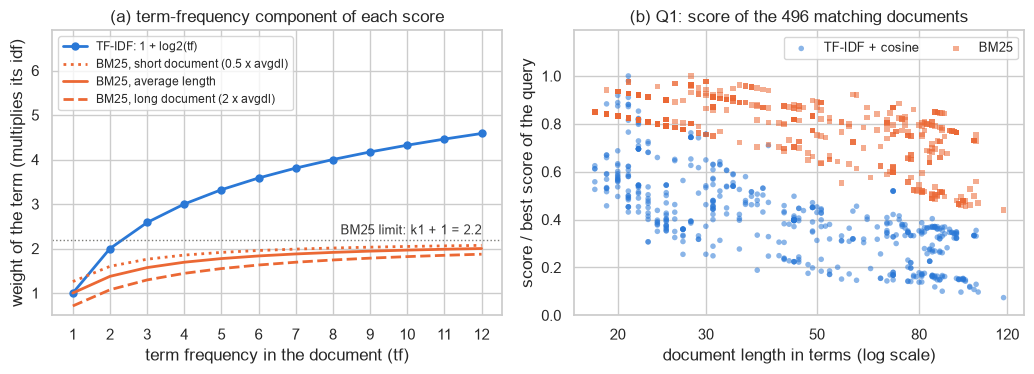

In [18]:
# Figure 1: (a) weight of a term as a function of its frequency, (b) score against document length for the 496 matches of Q1
BLUE, ORANGE, GREY = COLORS["tfidf"], COLORS["bm25"], "#7a7a76"
fig, axes = plt.subplots(1, 2, figsize=(10.5, 3.9))
ax = axes[0]
tf = np.arange(1, 13)
k1, b = 1.2, 0.75
ax.plot(tf, 1 + np.log2(tf), color=BLUE, lw=2, marker="o", ms=5, label="TF-IDF: 1 + log2(tf)")
for ratio, style, name in [(0.5, ":", "short document (0.5 x avgdl)"), (1.0, "-", "average length"), (2.0, "--", "long document (2 x avgdl)")]:
    ax.plot(tf, tf * (k1 + 1) / (tf + k1 * (1 - b + b * ratio)), color=ORANGE, lw=2, ls=style, label=f"BM25, {name}")
ax.axhline(k1 + 1, color=GREY, lw=1, ls=":")
ax.text(12, k1 + 1.06, "BM25 limit: k1 + 1 = 2.2", ha="right", va="bottom", fontsize=9, color="#333")
ax.set(xlabel="term frequency in the document (tf)", ylabel="weight of the term (multiplies its idf)",
       title="(a) term-frequency component of each score", xticks=range(1, 13, 1), ylim=(0.5, 6.9))
ax.legend(fontsize=8.5, loc="upper left")

ax = axes[1]
q = "Q1"
docs = [pid_pos[p] for p in runs["tfidf"][q]]
for m, color, marker in [("tfidf", BLUE, "o"), ("bm25", ORANGE, "s")]:
    score = dict(results[m][q])
    s = np.array([score[index.pids[d]] for d in docs])
    ax.scatter(doc_len[docs], s / s.max(), s=16, color=color, marker=marker, alpha=0.55, edgecolor="none", label=NAMES[m])
ax.set_xscale("log")
ax.set_xticks([20, 30, 50, 80, 120])
ax.set_xticklabels(["20", "30", "50", "80", "120"])
ax.minorticks_off()
ax.set(xlabel="document length in terms (log scale)", ylabel="score / best score of the query",
       title=f"(b) {q}: score of the {len(docs)} matching documents", ylim=(0, 1.19))
ax.legend(fontsize=9, loc="upper right", ncol=2)
savefig("tfidf_vs_bm25")

The two rankings are correlated (Kendall's τ between 0.72 and 0.84) but their first positions are often different
documents: the products are near-duplicates with almost the same score, so a small change in the formula reorders them.
Both scores prefer short documents (correlation between score and log-length of about −0.8 for both). The cosine does it more:
its top-10 documents are shorter, because its norm grows with every term of the document. BM25 accepts a longer document
when it repeats the query terms (in Q1 its first results have term frequencies 3-3-3-3-1 and 28-30 terms; the first results
of the cosine have 1-2-2-3-1 and 20-21 terms). Figure 1(a) shows the term-frequency part alone: in TF-IDF it keeps growing
(but the norm of the cosine grows with it), in BM25 it is bounded by k1 + 1.

## 3.3 BM25 parameters

`k1` controls how fast the term frequency saturates and `b` how much the length of the document is normalised
(`b = 0`: no normalisation, `b = 1`: full normalisation). The defaults (`k1 = 1.2`, `b = 0.75`) are used everywhere else.

In [19]:
grid = []
for k1 in (0.5, 1.2, 2.0):
    for b in (0.0, 0.5, 0.75, 1.0):
        ev = evaluate(run_ranker(Bm25Ranker(index, k1=k1, b=b)))
        grid.append({"k1": k1, "b": b, **{c: ev[c] for c in ["val MAP", "test MAP", "test P@10", "test NDCG@10"] + AP_COLS}})
bm25_grid = pd.DataFrame(grid)
bm25_grid.round(3).to_csv(os.path.join(RES_DIR, "bm25_parameters.csv"), index=False)
bm25_grid.round(3)

,k1,b,val MAP,test MAP,test P@10,test NDCG@10,AP Q1,AP Q2,AP T1,AP T2,AP T3,AP T4,AP T5
0,0.5,0.00,0.764,0.689,0.78,0.787,0.990,0.538,0.794,0.042,0.810,0.806,0.991
1,0.5,0.50,0.766,0.732,0.82,0.813,0.973,0.558,0.834,0.062,0.805,0.961,0.997
2,0.5,0.75,0.778,0.736,0.82,0.817,0.970,0.586,0.841,0.083,0.802,0.958,0.997
3,0.5,1.00,0.778,0.745,0.86,0.852,0.970,0.586,0.835,0.145,0.797,0.954,0.994
4,1.2,0.00,0.764,0.687,0.78,0.787,0.990,0.538,0.789,0.040,0.810,0.807,0.986
5,1.2,0.50,0.769,0.731,0.82,0.813,0.980,0.558,0.835,0.060,0.805,0.961,0.996
6,1.2,0.75,0.772,0.736,0.82,0.817,0.970,0.575,0.839,0.083,0.804,0.956,0.996
7,1.2,1.00,0.778,0.745,0.86,0.852,0.970,0.586,0.835,0.147,0.799,0.951,0.992
8,2.0,0.00,0.764,0.677,0.78,0.787,0.990,0.538,0.788,0.038,0.810,0.766,0.983
9,2.0,0.50,0.759,0.731,0.82,0.813,0.980,0.538,0.833,0.059,0.807,0.961,0.993


`k1` has almost no effect (the term frequencies of this collection are small), `b` has a clear one: without length
normalisation (`b = 0`) the test MAP falls, mainly in T4, where long descriptions that only mention a shirt go up. In this
collection the short documents are the plain product listings, so penalising length helps.

## 3.4 Evaluation of the two rankings with the judgments of Part 2

In [20]:
display(comparison.loc[[NAMES["tfidf"], NAMES["bm25"]], MAIN_COLS + ["test MRR"]].round(3))
display(comparison.loc[[NAMES["tfidf"], NAMES["bm25"]], AP_COLS].round(3))
two = per_query[per_query.method.isin([NAMES["tfidf"], NAMES["bm25"]])]
display(two.pivot(index="query", columns="method", values=["P@10", "NDCG@10", "RR"]).round(3))
# range of the scores and number of different values: the cosine is bounded by 1, BM25 depends on the query
display(two.pivot(index="query", columns="method", values=["best score", "lowest score", "distinct scores"]).round(2).assign(matches=two.groupby("query")["AND matches"].first()))

,val MAP,val NDCG@10,test MAP,test P@10,test P@20,test NDCG@10,test MRR
TF-IDF + cosine,0.764,0.859,0.737,0.86,0.85,0.885,1.00
BM25,0.772,0.859,0.736,0.82,0.82,0.817,0.84


,AP Q1,AP Q2,AP T1,AP T2,AP T3,AP T4,AP T5
TF-IDF + cosine,0.954,0.575,0.836,0.115,0.810,0.940,0.981
BM25,0.970,0.575,0.839,0.083,0.804,0.956,0.996


P@10                 NDCG@10                   RR                
method BM25 TF-IDF + cosine    BM25 TF-IDF + cosine BM25 TF-IDF + cosine
query                                                                   
Q1      1.0             1.0   1.000           1.000  1.0             1.0
Q2      0.6             0.6   0.718           0.718  1.0             1.0
T1      1.0             1.0   1.000           1.000  1.0             1.0
T2      0.1             0.3   0.085           0.425  0.2             1.0
T3      1.0             1.0   1.000           1.000  1.0             1.0
T4      1.0             1.0   1.000           1.000  1.0             1.0
T5      1.0             1.0   1.000           1.000  1.0             1.0

best score                 lowest score                 distinct scores                 matches
method       BM25 TF-IDF + cosine         BM25 TF-IDF + cosine            BM25 TF-IDF + cosine        
query                                                                                                 
Q1          14.14            0.80         6.22            0.06           240.0           427.0     496
Q2          13.92            0.56         5.63            0.08           128.0           187.0     224
T1          23.33            0.93        10.86            0.11            52.0            65.0      79
T2           9.15            0.63         3.74            0.04           694.0          1371.0    1584
T3          20.56            0.67         8.81            0.11            33.0            36.0      40
T4          13.34            0.76         4.13            0.05            64.0           100.0     114
T5          17.03            0.91         4.95            0.07            56.0            72.0      73

# 4. Our score

## 4.1 The numeric fields of a record

Part 1 parsed them as numbers and did not index them as text. They say nothing about *what* a product is, but they tell
whether the offer is good (rating, discount) and whether it can be bought (stock).

In [21]:
numeric = pd.DataFrame({
    "missing (%)": [100 * corpus[c].isna().mean() for c in ["average_rating", "discount", "selling_price", "actual_price"]] + [0.0],
    "min": [corpus[c].min() for c in ["average_rating", "discount", "selling_price", "actual_price"]] + [np.nan],
    "median": [corpus[c].median() for c in ["average_rating", "discount", "selling_price", "actual_price"]] + [np.nan],
    "mean": [corpus[c].mean() for c in ["average_rating", "discount", "selling_price", "actual_price"]] + [corpus.out_of_stock.mean()],
    "max": [corpus[c].max() for c in ["average_rating", "discount", "selling_price", "actual_price"]] + [np.nan],
}, index=["average_rating (1-5)", "discount (%)", "selling_price", "actual_price", "out_of_stock (share)"])
numeric.round(4).to_csv(os.path.join(RES_DIR, "numeric_fields.csv"))
print(numeric.round(2).to_string())
both = corpus[["average_rating", "discount", "selling_price"]].dropna()
print("\ncorrelations: rating-discount %.2f | rating-price %.2f | discount-price %.2f" % (
    both.average_rating.corr(both.discount), both.average_rating.corr(both.selling_price), both.discount.corr(both.selling_price)))

                      missing (%)    min  median     mean      max
average_rating (1-5)         8.05    1.0     3.8     3.63      5.0
discount (%)                 2.77    0.0    52.0    50.11     87.0
selling_price                0.01   99.0   545.0   705.64   7999.0
actual_price                 2.77  150.0  1199.0  1455.53  12999.0
out_of_stock (share)         0.00    NaN     NaN     0.06      NaN

correlations: rating-discount -0.05 | rating-price -0.01 | discount-price -0.29


## 4.2 Definition

$$\text{score}(q,d) = \underbrace{\text{BM25}(q,d)\,\big(1 + \lambda\,\text{title}(q,d)\big)}_{\text{text relevance}}
\;\cdot\; \underbrace{\big(1 + \alpha\,\text{rating}(d) + \beta\,\text{discount}(d)\big)}_{\text{quality of the offer}}
\;\cdot\; \underbrace{\text{stock}(d)}_{\text{availability}}$$

| Factor | Definition | Why |
|---|---|---|
| BM25(q, d) | BM25 on the merged field, as in section 3 | basis of the text relevance: saturated tf, soft length normalisation |
| title(q, d) | share of the distinct query terms that appear in the **title** (0..1) | Part 2 showed that many non-relevant results match a query term only in the description ("goes well with a denim jacket"). A product whose title contains the query words *is* that product |
| rating(d) | (average_rating − 1) / 4, in [0, 1]. Missing (8.1%) → mean of the collection | between two products that match equally, the better rated one is the better answer. The mean is a neutral value: an unrated product is neither rewarded nor punished |
| discount(d) | discount / 100, in [0, 1]. Missing (2.8%) → 0 | a discounted product is a more attractive offer. Weaker signal than the rating (it can be inflated by a high list price), so it has half the weight |
| stock(d) | 1 if in stock, γ if out of stock | a product that cannot be bought is a worse result, but it is still shown (at a lower position) |

Defaults: λ = 1, α = 0.5, β = 0.25, γ = 0.5. The numeric part multiplies the text score by a bounded factor (between 1 and
1 + α + β = 1.75), so it reorders documents with a similar text score and cannot bring a poor match to the top.
Price is not used: a cheaper product is not a more relevant one unless the user asks for it, so price belongs in a
filter or in a sort option, not in the relevance score.

In [22]:
custom = engines["custom"].ranker
print("parameters:", custom.params)
print("mean rating used for the products without rating: %.2f" % custom.mean_rating)
offer = custom.offer
print("offer factor (1 + alpha*rating + beta*discount) * stock over the collection: min %.2f | median %.2f | max %.2f" % (
    offer.min(), np.median(offer), offer.max()))

def explain(q, k=10):
    terms = pp.preprocess_text(QUERIES[q])
    bm25_rank = {pid: i for i, pid in enumerate(runs["bm25"][q], 1)}
    rows = []
    for rank, (pid, s) in enumerate(results["custom"][q][:k], 1):
        c = custom.components(terms, pid_pos[pid])
        rows.append({"rank": rank, "rank BM25": bm25_rank[pid], "title": corpus.loc[pid, "title"][:40], "BM25": round(c["bm25"], 2),
                     "title match": round(c["title"], 2), "rating": corpus.loc[pid, "average_rating"],
                     "discount": corpus.loc[pid, "discount"], "out of stock": corpus.loc[pid, "out_of_stock"],
                     "score": round(s, 2), "rel": int(pid in relevant[q])})
    return pd.DataFrame(rows).set_index("rank")

print("\nT5:", QUERIES["T5"])
display(explain("T5"))
print("T1:", QUERIES["T1"])
display(explain("T1"))

parameters: CustomScoreParams(title_boost=1.0, rating_weight=0.5, discount_weight=0.25, out_of_stock_factor=0.5, k1=1.2, b=0.75)
mean rating used for the products without rating: 3.63
offer factor (1 + alpha*rating + beta*discount) * stock over the collection: min 0.55 | median 1.46 | max 1.71

T5: men denim jacket


,rank BM25,title,BM25,title match,rating,discount,out of stock,score,rel
rank,,,,,,,,,
1,10,Full Sleeve Solid Men Denim Jacket,16.70,1.0,4.0,53.0,False,50.34,1
2,1,Full Sleeve Solid Men Denim Jacket,17.03,1.0,NaN,53.0,False,49.75,1
3,8,Full Sleeve Solid Men Denim Jacket,16.70,1.0,3.7,53.0,False,49.09,1
4,9,Full Sleeve Solid Men Denim Jacket,16.70,1.0,3.7,53.0,False,49.09,1
5,13,Full Sleeve Washed Men Denim Jacket,16.14,1.0,3.8,63.0,False,48.66,1
6,14,Full Sleeve Washed Men Denim Riding Jack,16.13,1.0,3.3,65.0,False,46.79,1
7,18,Full Sleeve Solid Men Denim Jacket,15.99,1.0,3.6,53.0,False,46.60,1
8,19,Full Sleeve Solid Men Denim Jacket,15.99,1.0,3.6,53.0,False,46.60,1
9,20,Full Sleeve Solid Men Denim Jacket,15.89,1.0,3.6,53.0,False,46.33,1


T1: men black track pants polyester


,rank BM25,title,BM25,title match,rating,discount,out of stock,score,rel
rank,,,,,,,,,
1,5,"Solid Men Black, Dark Blue Track Pants",22.09,0.8,5.0,65.0,False,66.11,1
2,2,Solid Men Black Track Pants,23.11,0.8,3.7,70.0,False,62.92,1
3,6,Solid Men Black Track Pants,21.71,0.8,4.3,69.0,False,61.94,1
4,18,Solid Men Black Track Pants,20.80,0.8,5.0,28.0,False,58.78,1
5,3,Solid Men Black Track Pants,22.49,0.8,3.4,52.0,False,57.89,1
6,4,Solid Men Black Track Pants,22.29,0.8,3.5,52.0,False,57.87,1
7,23,Solid Men Black Track Pants,20.76,0.8,4.2,48.0,False,56.79,1
8,32,Solid Men Black Track Pants,20.27,0.8,4.3,50.0,False,56.09,1
9,8,Striped Men Black Track Pants,21.45,0.8,4.0,28.0,False,55.79,1


## 4.3 Effect on relevance and on the offers that are shown

The relevance judgments of Part 2 only say whether a product *is* what the query asks for; they do not say that a product
with rating 4.5 is a better answer than the same product with rating 2.1. So, besides the relevance metrics, we measure the
offers in the first positions (top 10 and top 20 of the seven queries).

In [23]:
def offer_quality(run, k):
    top = [p for q in QUERIES for p in run[q][:k]]
    d = corpus.loc[top]
    return {"documents": len(top), "mean rating (rated products)": d.average_rating.mean(),
            "without rating (%)": 100 * d.average_rating.isna().mean(), "mean discount (%)": d.discount.mean(),
            "out of stock (%)": 100 * d.out_of_stock.mean(), "median price": d.selling_price.median()}

quality = pd.DataFrame({(f"top {k}", NAMES[m]): offer_quality(runs[m], k) for k in (10, 20) for m in METHODS}).T
all_matches = corpus.loc[[p for q in QUERIES for p in runs["tfidf"][q]]]
quality.loc[("all matches", "(any order)"), :] = [len(all_matches), all_matches.average_rating.mean(), 100 * all_matches.average_rating.isna().mean(),
                                                  all_matches.discount.mean(), 100 * all_matches.out_of_stock.mean(), all_matches.selling_price.median()]
quality.round(2).to_csv(os.path.join(RES_DIR, "offer_quality.csv"))
display(quality.round(2))
display(comparison.loc[[NAMES["bm25"], NAMES["custom"]], MAIN_COLS].round(3))
display(comparison.loc[[NAMES["bm25"], NAMES["custom"]], AP_COLS].round(3))

documents  mean rating (rated products)  without rating (%)  mean discount (%)  out of stock (%)  median price
top 10      TF-IDF + cosine         70.0                          3.35               12.86              47.93             17.14         909.0
            BM25                    70.0                          3.63                8.57              54.17             12.86         739.5
            Our score               70.0                          4.03                1.43              57.14              0.00         786.5
            word2vec + cosine       70.0                          3.33                1.43              52.61             10.00         798.5
top 20      TF-IDF + cosine        140.0                          3.43               13.57              51.06             14.29         899.0
            BM25                   140.0                          3.48                8.57              51.21             11.43         834.0
            Our score              140.0                          3.97                1.43              56.54              0.00         849.0
            word2vec + cosine      140.0                          3.37               10.00              50.24             10.00         799.0
all matches (any order)           2610.0                          3.67               11.49              52.33              7.47         599.0

,val MAP,val NDCG@10,test MAP,test P@10,test P@20,test NDCG@10
BM25,0.772,0.859,0.736,0.82,0.82,0.817
Our score,0.766,0.829,0.731,0.80,0.82,0.800


,AP Q1,AP Q2,AP T1,AP T2,AP T3,AP T4,AP T5
BM25,0.970,0.575,0.839,0.083,0.804,0.956,0.996
Our score,0.947,0.586,0.843,0.049,0.800,0.987,0.977


## 4.4 Contribution of each factor

Each row adds one factor to the previous one, from plain BM25 to the complete score. The last rows remove one factor from
the complete score.

In [24]:
P = rk.CustomScoreParams
def custom_ranker(params):
    return rk.CustomRanker(index, corpus.title_terms.tolist(), corpus.average_rating.tolist(), corpus.discount.tolist(),
                           corpus.out_of_stock.tolist(), params)

variants = [
    ("BM25 only", P(title_boost=0, rating_weight=0, discount_weight=0, out_of_stock_factor=1)),
    ("+ title match (lambda = 1)", P(rating_weight=0, discount_weight=0, out_of_stock_factor=1)),
    ("+ rating (alpha = 0.5)", P(discount_weight=0, out_of_stock_factor=1)),
    ("+ discount (beta = 0.25)", P(out_of_stock_factor=1)),
    ("+ stock (gamma = 0.5) = our score", P()),
    ("our score without title match", P(title_boost=0)),
    ("our score without rating", P(rating_weight=0)),
    ("our score without discount", P(discount_weight=0)),
]
rows = []
for name, params in variants:
    run = run_ranker(custom_ranker(params))
    ev, oq = evaluate(run), offer_quality(run, 10)
    rows.append({"variant": name, "val MAP": ev["val MAP"], "test MAP": ev["test MAP"], "test P@10": ev["test P@10"],
                 "test NDCG@10": ev["test NDCG@10"], "rating top 10": oq["mean rating (rated products)"],
                 "discount top 10": oq["mean discount (%)"], "out of stock top 10 (%)": oq["out of stock (%)"],
                 **{c: ev[c] for c in AP_COLS}})
ablation = pd.DataFrame(rows).set_index("variant")
assert run_ranker(custom_ranker(variants[-4][1])) == runs["custom"]            # the complete variant is the engine of section 2
ablation.round(3).to_csv(os.path.join(RES_DIR, "custom_ablation.csv"))
display(ablation.iloc[:, :7].round(3))
display(ablation[AP_COLS].round(3))

,val MAP,test MAP,test P@10,test NDCG@10,rating top 10,discount top 10,out of stock top 10 (%)
variant,,,,,,,
BM25 only,0.772,0.736,0.82,0.817,3.630,54.174,12.857
+ title match (lambda = 1),0.777,0.747,0.82,0.817,3.617,54.464,12.857
+ rating (alpha = 0.5),0.766,0.733,0.80,0.800,4.174,52.464,12.857
+ discount (beta = 0.25),0.764,0.737,0.80,0.800,4.071,57.800,12.857
+ stock (gamma = 0.5) = our score,0.766,0.731,0.80,0.800,4.028,57.143,0.000
our score without title match,0.741,0.709,0.80,0.800,4.052,57.814,0.000
our score without rating,0.758,0.750,0.88,0.861,3.475,62.843,0.000
our score without discount,0.769,0.726,0.80,0.800,4.103,53.145,0.000


,AP Q1,AP Q2,AP T1,AP T2,AP T3,AP T4,AP T5
variant,,,,,,,
BM25 only,0.970,0.575,0.839,0.083,0.804,0.956,0.996
+ title match (lambda = 1),0.980,0.575,0.847,0.087,0.804,0.998,0.998
+ rating (alpha = 0.5),0.984,0.549,0.843,0.039,0.798,0.992,0.992
+ discount (beta = 0.25),0.980,0.549,0.846,0.047,0.803,0.993,0.997
+ stock (gamma = 0.5) = our score,0.947,0.586,0.843,0.049,0.800,0.987,0.977
our score without title match,0.914,0.569,0.835,0.046,0.800,0.924,0.941
our score without rating,0.947,0.569,0.844,0.136,0.801,0.990,0.980
our score without discount,0.951,0.586,0.840,0.039,0.795,0.984,0.971


The title match is the factor that improves relevance (T4 and T5: the products that only mention a shirt or
a jacket in the description go down). The rating, the discount and the stock do not change what the product is, so they
cannot improve these metrics; they change *which* of the matching products are shown first: better rated, more discounted and
in stock. The rating has a cost when the relevant products happen to be badly rated (T2: the V-neck T-shirts have rating 2.6).

## 4.5 Sensitivity to the weights

In [25]:
def sweep(name, values, make):
    rows = []
    for v in values:
        run = run_ranker(custom_ranker(make(v)))
        ev, oq = evaluate(run), offer_quality(run, 10)
        rows.append({"parameter": name, "value": v, "val MAP": ev["val MAP"], "test MAP": ev["test MAP"], "test P@10": ev["test P@10"],
                     "test NDCG@10": ev["test NDCG@10"], "rating top 10": oq["mean rating (rated products)"],
                     "discount top 10": oq["mean discount (%)"], "out of stock top 10 (%)": oq["out of stock (%)"]})
    return rows

sens = pd.DataFrame(
    sweep("alpha (rating)", [0, 0.25, 0.5, 1, 2, 4, 8], lambda v: P(rating_weight=v))
    + sweep("lambda (title)", [0, 0.5, 1, 2, 4], lambda v: P(title_boost=v))
    + sweep("beta (discount)", [0, 0.25, 0.5, 1, 2], lambda v: P(discount_weight=v))
    + sweep("gamma (stock)", [1, 0.75, 0.5, 0.25, 0], lambda v: P(out_of_stock_factor=v)))
sens.round(3).to_csv(os.path.join(RES_DIR, "custom_sensitivity.csv"), index=False)
sens.round(3)

,parameter,value,val MAP,test MAP,test P@10,test NDCG@10,rating top 10,discount top 10,out of stock top 10 (%)
0,alpha (rating),0.00,0.758,0.750,0.88,0.861,3.475,62.843,0.000
1,alpha (rating),0.25,0.758,0.735,0.82,0.813,3.916,59.014,0.000
2,alpha (rating),0.50,0.766,0.731,0.80,0.800,4.028,57.143,0.000
3,alpha (rating),1.00,0.772,0.725,0.80,0.800,4.180,54.014,0.000
4,alpha (rating),2.00,0.772,0.714,0.80,0.800,4.272,51.143,0.000
5,alpha (rating),4.00,0.763,0.705,0.78,0.787,4.314,50.271,0.000
6,alpha (rating),8.00,0.760,0.699,0.78,0.787,4.349,49.957,0.000
7,lambda (title),0.00,0.741,0.709,0.80,0.800,4.052,57.814,0.000
8,lambda (title),0.50,0.753,0.726,0.80,0.800,4.028,57.143,0.000
9,lambda (title),1.00,0.766,0.731,0.80,0.800,4.028,57.143,0.000


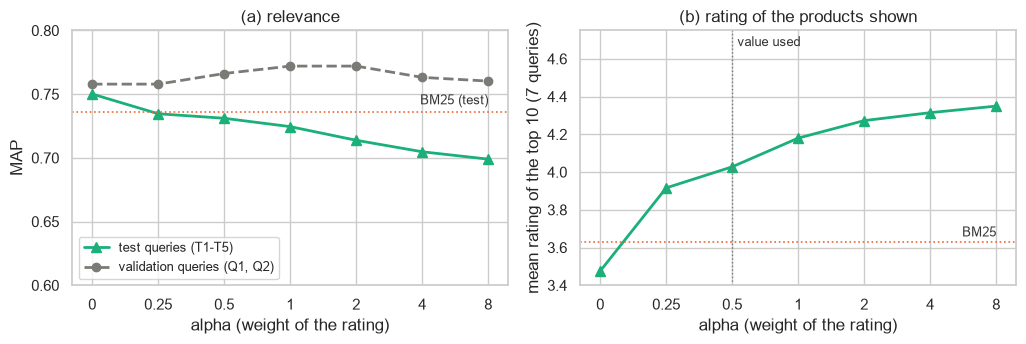

In [26]:
# Figure 2: the weight of the rating trades relevance (left) for the rating of the products that are shown (right)
a = sens[sens.parameter == "alpha (rating)"]
x = range(len(a))
fig, axes = plt.subplots(1, 2, figsize=(10.5, 3.6))
ax = axes[0]
ax.plot(x, a["test MAP"], color=COLORS["custom"], lw=2, marker="^", ms=7, label="test queries (T1-T5)")
ax.plot(x, a["val MAP"], color=GREY, lw=2, marker="o", ms=6, ls="--", label="validation queries (Q1, Q2)")
ax.axhline(comparison.loc[NAMES["bm25"], "test MAP"], color=COLORS["bm25"], lw=1.2, ls=":")
ax.text(len(a) - 1, comparison.loc[NAMES["bm25"], "test MAP"] + 0.004, "BM25 (test)", ha="right", va="bottom", fontsize=9, color="#333")
ax.set(xticks=list(x), xticklabels=[f"{v:g}" for v in a["value"]], xlabel="alpha (weight of the rating)", ylabel="MAP",
       title="(a) relevance", ylim=(0.6, 0.8))
ax.legend(fontsize=9, loc="lower left")
ax = axes[1]
ax.plot(x, a["rating top 10"], color=COLORS["custom"], lw=2, marker="^", ms=7)
bm25_rating = offer_quality(runs["bm25"], 10)["mean rating (rated products)"]
ax.axhline(bm25_rating, color=COLORS["bm25"], lw=1.2, ls=":")
ax.text(len(a) - 1, bm25_rating + 0.015, "BM25", ha="right", va="bottom", fontsize=9, color="#333")
ax.axvline(list(a["value"]).index(0.5), color=GREY, lw=1, ls=":")
ax.text(list(a["value"]).index(0.5) + 0.08, 4.72, "value used", fontsize=9, color="#333", va="top")
ax.set(xticks=list(x), xticklabels=[f"{v:g}" for v in a["value"]], xlabel="alpha (weight of the rating)",
       ylabel="mean rating of the top 10 (7 queries)", title="(b) rating of the products shown", ylim=(3.4, 4.75))
savefig("custom_score_rating_weight")

# 5. word2vec + cosine

## 5.1 Word vectors

**Decision: we train word2vec on our own collection** (gensim), on the same pre-processed terms that are in the index
(`all_terms`, one document = one sentence), instead of using pre-trained vectors. The terms of the index are stems
(`sleev`, `polyest`, `tshirt`) and brand names, which do not exist in a pre-trained vocabulary, and the query goes through the
same pre-processing, so every term that can pass the AND has a vector.

| Parameter | Value | Reason |
|---|---|---|
| architecture | CBOW (`sg=0`) | 4 times faster than skip-gram here and not worse in our tests (section 6) |
| `vector_size` | 100 | small corpus (1.26M tokens, 5,865 terms): more dimensions cannot be estimated |
| `window` | 5 | titles and product details are short lists of attributes |
| `min_count` | 1 | every term of the index gets a vector (the vectors of very rare terms are noisy, but each has little weight in the average of a document) |
| `negative`, `epochs` | 10, 30 | more passes than the default (5) because the corpus is small |
| `seed`, `workers` | 42, 1 | one thread and a hash function that does not change between sessions (`rk.stable_hash`) make the training reproducible |

The vectors are stored in `models/word2vec_fashion.bin` so that the lists below can be reproduced exactly.

In [27]:
w2v = engines["word2vec"].ranker
wv = w2v.wv
print("vocabulary:", len(wv), "terms | dimensions:", wv.vector_size, "| every term of the index has a vector:",
      all(t in wv.key_to_index for t in index.term_to_id))

words = ["jean", "tshirt", "jacket", "sweatshirt", "polyest", "grey", "stripe", "slim", "puma"]
neighbours = pd.DataFrame([{"term": w, "nearest terms (cosine)": ", ".join(f"{t} {s:.2f}" for t, s in wv.most_similar(w, topn=6))} for w in words])
neighbours.to_csv(os.path.join(RES_DIR, "word2vec_neighbours.csv"), index=False)
display(neighbours)

pairs = [("men", "women"), ("grey", "black"), ("blue", "black"), ("round", "neck"), ("polyest", "polycotton"), ("jean", "denim"),
         ("hood", "hoodi"), ("grey", "gray"), ("pant", "trouser"), ("shirt", "tshirt")]
pair_sim = pd.DataFrame([{"pair": f"{a} / {b}", "cosine": float(wv.similarity(a, b))} for a, b in pairs])
pair_sim.round(3).to_csv(os.path.join(RES_DIR, "word2vec_pairs.csv"), index=False)
pair_sim.round(2).T

vocabulary: 5865 terms | dimensions: 100 | every term of the index has a vector: True


,term,nearest terms (cosine)
0,jean,"denim 0.47, chino 0.39, tan 0.37, trouser 0.36, etch 0.34, loafer ..."
1,tshirt,"neck 0.49, polo 0.46, round 0.43, regimen 0.42, xxl 0.41, men 0.39"
2,jacket,"none 0.54, colorblock 0.51, sweater 0.45, sweatshirt 0.44, brn 0.4..."
3,sweatshirt,"pullov 0.57, sweater 0.45, jacket 0.44, hoodi 0.43, fleec 0.42, em..."
4,polyest,"polycotton 0.62, nylon 0.49, cotton 0.47, pure 0.45, linen 0.44, b..."
5,grey,"black 0.89, red 0.84, white 0.81, blue 0.81, maroon 0.79, green 0.79"
6,stripe,"solid 0.85, print 0.74, typographi 0.70, checker 0.69, block 0.59,..."
7,slim,"regular 0.82, western 0.49, white 0.43, women 0.43, sleev 0.42, re..."
8,puma,"reebok 0.48, livster 0.47, athliv 0.40, breakbounc 0.38, left 0.37..."


,0,1,2,3,4,5,6,7,8,9
pair,men / women,grey / black,blue / black,round / neck,polyest / polycotton,jean / denim,hood / hoodi,grey / gray,pant / trouser,shirt / tshirt
cosine,0.99,0.89,0.72,0.74,0.62,0.47,0.3,0.28,0.25,0.34


## 5.2 Representation of a text and score

A text (document or query) is one vector: the average of the vectors of all its words. The documents use the terms of
`all_terms` (the field that is indexed) and the score is the cosine between the query vector and the document vector.
The check below recomputes one document vector and one score by hand.

In [28]:
pid = runs["word2vec"]["T5"][0]
d = pid_pos[pid]
terms_d = corpus.loc[pid, "all_terms"]
v_d = np.mean([wv[t] for t in terms_d], axis=0)                       # average of the word vectors of the document
terms_q = pp.preprocess_text(QUERIES["T5"])
v_q = np.mean([wv[t] for t in terms_q], axis=0)                       # average of the word vectors of the query
cos = float(v_d @ v_q / (np.linalg.norm(v_d) * np.linalg.norm(v_q)))
print("document", pid, "|", len(terms_d), "terms | query terms:", terms_q)
print("cosine by hand: %.6f | score of the ranker: %.6f" % (cos, dict(results["word2vec"]["T5"])[pid]))
assert abs(cos - dict(results["word2vec"]["T5"])[pid]) < 1e-5
assert np.allclose(w2v.doc_vectors[d], v_d / np.linalg.norm(v_d), atol=1e-6)

document JCKFMHKMYEWHQFNU | 54 terms | query terms: ['men', 'denim', 'jacket']
cosine by hand: 0.836168 | score of the ranker: 0.836168


## 5.3 Top-20 lists for the five queries of Part 2

Conjunctive search + word2vec cosine ranking. `rel` is our relevance judgment of Part 2 (1 = relevant), shown only to read the
lists; it is not used by the ranking. The lists are saved in `results/word2vec_top20.csv`.

In [29]:
rows = []
for q, text in TEST_QUERIES.items():
    for rank, (pid, s) in enumerate(results["word2vec"][q][:20], 1):
        r = corpus.loc[pid]
        rows.append({"query_id": q, "query": text, "rank": rank, "score": round(s, 4), "pid": pid, "title": r["title"],
                     "brand": r["brand"], "selling_price": r["selling_price"], "average_rating": r["average_rating"],
                     "rel": int(pid in relevant[q])})
top20 = pd.DataFrame(rows)
top20.to_csv(os.path.join(RES_DIR, "word2vec_top20.csv"), index=False)
for q, text in TEST_QUERIES.items():
    n = len(runs["word2vec"][q])
    print(f"{q}: {text!r} | terms {pp.preprocess_text(text)} | {n} documents contain all the terms")
    display(top20[top20.query_id == q].drop(columns=["query_id", "query"]).set_index("rank"))

T1: 'men black track pants polyester' | terms ['men', 'black', 'track', 'pant', 'polyest'] | 79 documents contain all the terms


,score,pid,title,brand,selling_price,average_rating,rel
rank,,,,,,,
1,0.8764,TKPFZDVZVQHWEUVF,Solid Men Black Track Pants,Onei,599.0,3.7,1
2,0.8739,TKPFZMZSWZN5HKEZ,Solid Men Black Track Pants,None,349.0,2.1,1
3,0.8380,TKPFZAZ4QCAZFAGA,"Solid Men Black, Dark Blue Track Pants",Onei,699.0,5.0,1
4,0.8191,TKPF3FPQGCHXHGRM,"Solid Men Black, Grey Track Pants",Fairdea,538.0,2.6,1
5,0.8191,TKPF3FPNZ5XCHZ6R,"Solid Men Black, Grey Track Pants",Fairdea,538.0,2.6,1
6,0.8191,TKPF3FPKTYM55SAV,"Solid Men Black, Grey Track Pants",Fairdea,538.0,2.6,1
7,0.8172,TKPFZDKXX7MQAYYK,Solid Men Black Track Pants,Ravil,474.0,3.4,1
8,0.8157,TKPF3FPJNVVBKPRG,"Solid Men Blue, Black Track Pants",Fairdea,631.0,2.6,1
9,0.8157,TKPF3FPZRRJUWTAZ,"Solid Men Blue, Black Track Pants",Fairdea,538.0,2.6,1


T2: 'women black v neck tshirt' | terms ['women', 'black', 'neck', 'tshirt'] | 1584 documents contain all the terms


,score,pid,title,brand,selling_price,average_rating,rel
rank,,,,,,,
1,0.9426,TSHFYUQYXW4BY9GR,"Striped Women Round Neck Black, White T-Shirt",Steenb,399.0,3.7,0
2,0.9425,TSHEYRU4NH2ERTGV,"Abstract Women V-Neck Black, Yellow T-Shirt",Fairdea,284.0,2.6,1
3,0.9424,TSHEYQ73G7VKU9WN,"Chevron/Zig Zag Women V-Neck Red, Black T-Shirt",Fairdea,284.0,2.6,1
4,0.9420,TSHF3MHQKA4NWX2Y,"Printed Women V-neck Black, Yellow T-Shirt",Fairdea,284.0,2.6,1
5,0.9416,TSHF3MHNGFFAKPB4,"Solid Women V-neck Black, Yellow T-Shirt",Fairdea,284.0,2.6,1
6,0.9416,TSHF3MHZGSEHCBQ4,"Solid Women V-neck Black, Yellow T-Shirt",Fairdea,284.0,2.6,1
7,0.9410,TSHEYRU3TH46Z4Z3,"Abstract Women V-Neck Blue, Black T-Shirt",Fairdea,284.0,2.6,1
8,0.9394,TSHFDHGJQNM39YYN,Color Block Women Round Neck Black T-Shirt,Amp,349.0,3.4,0
9,0.9393,TSHFWF57CTFWRGFZ,Solid Women Round Neck Black T-Shirt,MASH UNLIMIT,329.0,3.2,0


T3: 'men grey hooded sweatshirt' | terms ['men', 'grey', 'hood', 'sweatshirt'] | 40 documents contain all the terms


,score,pid,title,brand,selling_price,average_rating,rel
rank,,,,,,,
1,0.8398,SWSFXMKRJYMSYTTA,Full Sleeve Solid Men Sweatshirt,Breakboun,749.0,NaN,1
2,0.8382,SWSFZ7GXWNGANCUA,Sleeveless Solid Men Sweatshirt,LIVST,799.0,3.3,1
3,0.8376,SWSFXMKPWFS9HRGS,Full Sleeve Printed Men Sweatshirt,Breakboun,849.0,2.8,1
4,0.8249,SWSFZUEBEBWJUQWG,Full Sleeve Printed Men Sweatshirt,RELIEF ZO,849.0,4.3,1
5,0.8198,SWSFYNY4CWHCDWM5,Full Sleeve Printed Men Sweatshirt,MASH UNLIMIT,649.0,3.2,1
6,0.8178,SWSFHABMCWFP8GJR,Sleeveless Solid Men Sweatshirt,TeeMoo,799.0,3.0,1
7,0.8174,SWSFZKX9T2SGSKRA,Full Sleeve Color Block Men Sweatshirt,REEB,1749.0,2.4,1
8,0.8127,SWSFVEMQPH2V96BF,Full Sleeve Printed Men Sweatshirt,Steenb,899.0,3.7,1
9,0.8092,SWSFYQFQZTYY3YVM,Full Sleeve Printed Men Sweatshirt,Rose We,273.0,3.2,1


T4: 'women striped shirt' | terms ['women', 'stripe', 'shirt'] | 114 documents contain all the terms


,score,pid,title,brand,selling_price,average_rating,rel
rank,,,,,,,
1,0.8777,SHTFAHDZ7H9ZFYNZ,Women Slim Fit Striped Spread Collar Casual Shirt,Purple Sta,629.0,3.8,1
2,0.8738,SHTFAHDYU7QAHTEZ,Women Regular Fit Striped Casual Shirt,Purple Sta,629.0,2.9,1
3,0.8682,SHTFCA3J7UZ2TGHN,Women Regular Fit Striped Formal Shirt,Mo,775.0,4.8,1
4,0.8639,SHTFHPZ7HYGXGJK6,Women Slim Fit Striped Casual Shirt,SUR,699.0,4.0,1
5,0.8637,SHTFHPZ7WFH8NKRT,Women Slim Fit Striped Casual Shirt,SUR,699.0,4.0,1
6,0.8632,SHTFHPZ7YTVWZWHW,Women Slim Fit Striped Casual Shirt,SUR,699.0,4.0,1
7,0.8632,SHTFYW8Z4EHRRT8Y,Women Slim Fit Striped Casual Shirt,Purple Sta,629.0,2.9,1
8,0.8616,SHTFWHDQJ34GDCHQ,Women Slim Fit Striped Casual Shirt,AS Tre,399.0,3.7,1
9,0.8616,SHTFWHDQRKZJB4VT,Women Slim Fit Striped Casual Shirt,AS Tre,399.0,3.7,1


T5: 'men denim jacket' | terms ['men', 'denim', 'jacket'] | 73 documents contain all the terms


,score,pid,title,brand,selling_price,average_rating,rel
rank,,,,,,,
1,0.8362,JCKFMHKMYEWHQFNU,Full Sleeve Printed Men Denim Casual Jacket,Solid Styl,1424.0,3.3,1
2,0.8136,JCKFKKFZ7QB2KUQV,Full Sleeve Washed Men Denim Jacket,Solid Styl,1443.0,3.8,1
3,0.8106,JCKFKKFZMDEHEZQS,Full Sleeve Washed Men Denim Jacket,Solid Styl,1424.0,2.4,1
4,0.8030,JCKFWC5ZHSAEVYMS,Full Sleeve Solid Men Denim Jacket,VOXA,1199.0,3.7,1
5,0.8013,JCKFZJWZNCGGZGSE,Full Sleeve Washed Men Denim Jacket,saltla,1200.0,2.9,1
6,0.8013,JCKFZJWZBZCCTYXM,Full Sleeve Washed Men Denim Jacket,saltla,1200.0,2.9,1
7,0.8011,JCKFYY97BC7KWPM4,Full Sleeve Solid Men Denim Jacket,VOXA,1199.0,3.7,1
8,0.8002,JCKFURYWGYKVKFH3,Full Sleeve Solid Men Denim Jacket,VOXA,1199.0,3.7,1
9,0.8000,JCKFVDPW4WNPBGS2,Full Sleeve Solid Men Denim Jacket,VOXA,1199.0,3.7,1


In [30]:
# the top 20 of the four methods, to compare them (also used for the summary)
rows = []
for m in METHODS:
    for q, text in QUERIES.items():
        for rank, (pid, s) in enumerate(results[m][q][:20], 1):
            rows.append({"method": m, "query_id": q, "rank": rank, "score": round(s, 4), "pid": pid, "title": corpus.loc[pid, "title"],
                         "doc_length": int(doc_len[pid_pos[pid]]),
                         "rel": qrels[q].get(pid, 0) if q in TEST_QUERIES else qrels[q].get(pid, np.nan)})
pd.DataFrame(rows).to_csv(os.path.join(RES_DIR, "top20_all_methods.csv"), index=False)

# word2vec ranking: range of the scores, length of the top documents, agreement with the other rankings
rows = []
for q in QUERIES:
    s = np.array([x for _, x in results["word2vec"][q]])
    top = runs["word2vec"][q][:20]
    rows.append({"query": q, "AND matches": len(s), "cosine min": s.min(), "cosine median": np.median(s), "cosine of rank 20": s[min(19, len(s) - 1)],
                 "cosine max": s.max(), "mean length top 20": doc_len[[pid_pos[p] for p in top]].mean(),
                 "mean length all matches": doc_len[[pid_pos[p] for p in runs["word2vec"][q]]].mean(),
                 "common top 20 with TF-IDF": len(set(top) & set(runs["tfidf"][q][:20])),
                 "common top 20 with BM25": len(set(top) & set(runs["bm25"][q][:20])),
                 "relevant in top 20": sum(p in relevant[q] for p in top) if q in TEST_QUERIES else np.nan})
w2v_stats = pd.DataFrame(rows).set_index("query")
w2v_stats.round(3).to_csv(os.path.join(RES_DIR, "word2vec_ranking_stats.csv"))
display(w2v_stats.round(2))
display(comparison[MAIN_COLS].round(3))
display(comparison[AP_COLS].round(3))

,AND matches,cosine min,cosine median,cosine of rank 20,cosine max,mean length top 20,mean length all matches,common top 20 with TF-IDF,common top 20 with BM25,relevant in top 20
query,,,,,,,,,,
Q1,496,0.47,0.86,0.92,0.93,25.25,50.00,6,12,NaN
Q2,224,0.30,0.73,0.83,0.85,30.30,50.36,3,5,NaN
T1,79,0.27,0.72,0.75,0.88,27.30,34.66,9,15,19.0
T2,1584,0.25,0.88,0.93,0.94,28.00,54.84,1,6,8.0
T3,40,0.43,0.75,0.76,0.84,32.20,51.42,15,16,19.0
T4,114,-0.02,0.78,0.84,0.88,21.40,60.45,10,13,20.0
T5,73,0.10,0.67,0.75,0.84,34.05,71.47,13,17,20.0


,val MAP,val NDCG@10,test MAP,test P@10,test P@20,test NDCG@10
TF-IDF + cosine,0.764,0.859,0.737,0.86,0.85,0.885
BM25,0.772,0.859,0.736,0.82,0.82,0.817
Our score,0.766,0.829,0.731,0.80,0.82,0.800
word2vec + cosine,0.745,0.843,0.745,0.94,0.86,0.929


,AP Q1,AP Q2,AP T1,AP T2,AP T3,AP T4,AP T5
TF-IDF + cosine,0.954,0.575,0.836,0.115,0.810,0.940,0.981
BM25,0.970,0.575,0.839,0.083,0.804,0.956,0.996
Our score,0.947,0.586,0.843,0.049,0.800,0.987,0.977
word2vec + cosine,0.976,0.513,0.807,0.220,0.795,0.919,0.984


The cosines of the matching documents are packed in a narrow band (in T2 the first 20 results are between 0.93
and 0.94): all the documents are fashion products described with the same words, so their average vectors are close to each
other and the order of the first positions depends on small differences. Like the two lexical scores, the average prefers
short documents (a long description adds many generic words to the average).

## 5.4 What the vectors can and cannot do: the same ranking without the AND

The pipeline of this part only lets word2vec re-order the documents that already contain all the query terms. Its expected
advantage (finding documents that use related words) cannot appear there, so we also rank the whole collection by cosine,
without the AND filter, and we look at where the relevant documents fall. This is only an analysis: it is not the pipeline
of the assignment.

In [31]:
all_docs = list(range(index.num_docs))
rows = []
for q, text in QUERIES.items():
    terms = pp.preprocess_text(text)
    full = [index.pids[d] for d, _ in w2v.score(terms, all_docs)]                 # whole collection ranked by cosine
    pos = {p: i for i, p in enumerate(full, 1)}
    and_ranked = runs["word2vec"][q]
    lost = sorted(pos[p] for p in relevant[q] - set(and_ranked))                  # relevant documents that the AND does not return
    hybrid = and_ranked + [p for p in full if p not in set(and_ranked)]           # AND results first, then the rest by cosine
    is_val = q in VALIDATION_QUERIES
    ap = lambda run: evaluate_run({q: condense(run, qrels[q]) if is_val else run}, {q: qrels[q]}, (10,)).loc[q, "AP"]
    rows.append({"query": q, "R": len(relevant[q]), "relevant not returned by the AND": len(lost),
                 "their ranks without the AND": ", ".join(map(str, lost[:6])) + (" ..." if len(lost) > 6 else ""),
                 "P@20 without AND": np.nan if is_val else sum(p in relevant[q] for p in full[:20]) / 20,
                 "P@20 with AND": np.nan if is_val else sum(p in relevant[q] for p in and_ranked[:20]) / 20,
                 "AP without AND": ap(full), "AP with AND": ap(and_ranked), "AP: AND first, then the rest": ap(hybrid)})
without_and = pd.DataFrame(rows).set_index("query")
without_and.round(3).to_csv(os.path.join(RES_DIR, "word2vec_without_and.csv"))
without_and.round(3)

,R,relevant not returned by the AND,their ranks without the AND,P@20 without AND,P@20 with AND,AP without AND,AP with AND,"AP: AND first, then the rest"
query,,,,,,,,
Q1,13,0,,NaN,NaN,0.976,0.976,0.976
Q2,10,4,"47, 92, 106, 515",NaN,NaN,0.696,0.513,0.782
T1,79,11,"60, 243, 403, 448, 516, 749 ...",0.15,0.95,0.099,0.807,0.825
T2,43,0,,0.35,0.40,0.106,0.220,0.220
T3,48,9,"620, 656, 705, 732, 2132, 2133 ...",0.00,0.95,0.037,0.795,0.801
T4,74,0,,0.05,1.00,0.042,0.919,0.919
T5,38,0,,0.65,1.00,0.540,0.984,0.984


Without the AND the average vector cannot keep the attributes of the query: precision at 20 falls for every
query, because a product with another gender or another colour is almost as close to the query as the right one
(`men` / `women` have cosine 0.99, `grey` / `black` 0.89). The useful part is the opposite one: the relevant documents that
the AND loses (T1, T3, Q2) get a position, and putting them **after** the AND results improves AP in the queries where the
AND loses documents and changes nothing in the others.

# 6. Better representations than the average of word2vec vectors

The average gives the same weight to every word (`women` or `cotton`, which are in half of the collection, count as much
as `denim`), ignores the order of the words, and in a long description the few words that matter are diluted among many
generic ones. We compare, with the same pipeline and the same judgments:

| Representation | What changes |
|---|---|
| word2vec average, CBOW (section 5) | reference |
| word2vec average, skip-gram | other training algorithm for the word vectors |
| IDF-weighted average | every word vector is weighted by `log2(N / df)`, so rare words count more |
| SIF (Arora et al., 2017), a "sentence2vec" baseline | weights `a / (a + p(w))` with `a = 0.001` and removal of the first principal component |
| average of the title only | the document vector uses only the title terms (no dilution by the description) |
| doc2vec PV-DBOW / PV-DM (Le & Mikolov, 2014) | one vector per document learned by the model; the query vector is inferred |

The word vectors of the first rows are the ones of section 5; the skip-gram and doc2vec models are trained here (about 2
minutes in total). They are not stored: on another machine their numbers can change in the third decimal.

In [32]:
term_lists = corpus.all_terms.tolist()
N = index.num_docs
idf_weights = {t: index.idf(t) for t in index.term_to_id}
total_terms = int(doc_len.sum())
collection_freq = {t: sum(tf for _, tf in index.get_postings(t)) for t in index.term_to_id}
a = 1e-3
sif_weights = {t: a / (a + cf / total_terms) for t, cf in collection_freq.items()}

representations, timing = {}, {}
def add(name, build):
    t0 = time.time()
    ranker = build()
    representations[name] = run_ranker(ranker)
    timing[name] = time.time() - t0
    print("%-42s %5.1f s" % (name, timing[name]))

add("word2vec average, CBOW (section 5)", lambda: rk.Word2VecRanker(wv, term_lists))
add("word2vec average, skip-gram", lambda: rk.Word2VecRanker(rk.train_word2vec(term_lists, sg=1, epochs=10), term_lists))
add("IDF-weighted average", lambda: rk.Word2VecRanker(wv, term_lists, term_weights=idf_weights))
add("SIF: weighted average - 1st component", lambda: rk.Word2VecRanker(wv, term_lists, term_weights=sif_weights, remove_first_component=True))
add("average of the title only", lambda: rk.Word2VecRanker(wv, corpus.title_terms.tolist()))
add("doc2vec PV-DBOW", lambda: rk.Doc2VecRanker(rk.train_doc2vec(term_lists, dm=0)))
add("doc2vec PV-DM", lambda: rk.Doc2VecRanker(rk.train_doc2vec(term_lists, dm=1)))
assert representations["word2vec average, CBOW (section 5)"] == runs["word2vec"]

rep_table = pd.DataFrame({name: evaluate(run) for name, run in representations.items()}).T
rep_table["build time (s)"] = pd.Series(timing)
rep_table.round(3).to_csv(os.path.join(RES_DIR, "representations.csv"))
display(rep_table[MAIN_COLS + ["build time (s)"]].round(3))
display(rep_table[AP_COLS].round(3))

word2vec average, CBOW (section 5)           1.0 s
word2vec average, skip-gram                 58.2 s
IDF-weighted average                         1.0 s
SIF: weighted average - 1st component        1.3 s
average of the title only                    0.4 s
doc2vec PV-DBOW                             30.8 s
doc2vec PV-DM                               38.3 s


,val MAP,val NDCG@10,test MAP,test P@10,test P@20,test NDCG@10,build time (s)
"word2vec average, CBOW (section 5)",0.745,0.843,0.745,0.94,0.86,0.929,1.017
"word2vec average, skip-gram",0.729,0.843,0.716,0.80,0.79,0.800,58.173
IDF-weighted average,0.738,0.843,0.715,0.82,0.81,0.814,0.956
SIF: weighted average - 1st component,0.749,0.816,0.703,0.80,0.79,0.800,1.292
average of the title only,0.667,0.726,0.813,0.96,0.97,0.967,0.415
doc2vec PV-DBOW,0.740,0.820,0.700,0.80,0.76,0.800,30.815
doc2vec PV-DM,0.749,0.845,0.700,0.84,0.81,0.826,38.270


,AP Q1,AP Q2,AP T1,AP T2,AP T3,AP T4,AP T5
"word2vec average, CBOW (section 5)",0.976,0.513,0.807,0.220,0.795,0.919,0.984
"word2vec average, skip-gram",0.944,0.513,0.829,0.046,0.794,0.934,0.976
IDF-weighted average,0.963,0.513,0.822,0.065,0.791,0.919,0.979
SIF: weighted average - 1st component,0.959,0.538,0.824,0.022,0.795,0.898,0.977
average of the title only,0.833,0.501,0.830,0.491,0.774,0.995,0.975
doc2vec PV-DBOW,0.933,0.546,0.825,0.045,0.792,0.937,0.903
doc2vec PV-DM,0.975,0.524,0.842,0.075,0.808,0.956,0.822


In [33]:
# Length of the documents that each one puts first
t2 = pd.DataFrame({name: {"mean length top 20 (all_terms)": doc_len[[pid_pos[p] for p in run["T2"][:20]]].mean(),
                          "mean title length top 20": np.mean([len(corpus.loc[p, "title_terms"]) for p in run["T2"][:20]]),
                          "relevant in top 20": sum(p in relevant["T2"] for p in run["T2"][:20])}
                   for name, run in {**{NAMES[m]: runs[m] for m in ("tfidf", "bm25")}, **representations}.items()}).T
rel_t2 = [p for p in runs["tfidf"]["T2"] if p in relevant["T2"]]
print("T2 (%s): %d matches, %d relevant" % (QUERIES["T2"], len(runs["tfidf"]["T2"]), len(rel_t2)))
print("mean length of the relevant documents: %.1f terms | of all the matches: %.1f" % (
    doc_len[[pid_pos[p] for p in rel_t2]].mean(), doc_len[[pid_pos[p] for p in runs["tfidf"]["T2"]]].mean()))
print("mean title length of the relevant documents: %.1f terms | of all the matches: %.1f" % (
    np.mean([len(corpus.loc[p, "title_terms"]) for p in rel_t2]), np.mean([len(corpus.loc[p, "title_terms"]) for p in runs["tfidf"]["T2"]])))
t2_rel_rating = corpus.loc[rel_t2, "average_rating"]
t2_facts = {"relevant": len(rel_t2), "mean rating of the relevant documents": float(t2_rel_rating.mean()),
            "relevant documents with rating 2.6": int((t2_rel_rating == 2.6).sum()),
            "mean rating of all the matches": float(corpus.loc[runs["tfidf"]["T2"], "average_rating"].mean())}
print("ratings in T2:", {k: round(v, 2) for k, v in t2_facts.items()})
# validation queries: titles that appear both among the relevant and among the non-relevant judged documents
for q in VALIDATION_QUERIES:
    g = labels[labels.query_id == int(q[1])]
    shared = sorted(set(g[g.labels == 1].title) & set(g[g.labels == 0].title))
    print(f"{q}: titles shared by relevant and non-relevant judged documents:", shared)
t2.round(2).to_csv(os.path.join(RES_DIR, "t2_top20_by_representation.csv"))
t2.round(2)

T2 (women black v neck tshirt): 1584 matches, 43 relevant
mean length of the relevant documents: 39.8 terms | of all the matches: 54.8
mean title length of the relevant documents: 6.2 terms | of all the matches: 6.6
ratings in T2: {'relevant': 43, 'mean rating of the relevant documents': 3.19, 'relevant documents with rating 2.6': 15, 'mean rating of all the matches': 3.68}
Q1: titles shared by relevant and non-relevant judged documents: ['Full Sleeve Printed Women Sweatshirt', 'Full Sleeve Solid Women Sweatshirt']
Q2: titles shared by relevant and non-relevant judged documents: ['Slim Men Blue Jeans', 'Slim Women Blue Jeans', 'Super Skinny Women Blue Jeans', 'Tapered Fit Men Blue Jeans']


,mean length top 20 (all_terms),mean title length top 20,relevant in top 20
TF-IDF + cosine,25.50,5.75,5.0
BM25,31.70,6.15,2.0
"word2vec average, CBOW (section 5)",28.00,6.50,8.0
"word2vec average, skip-gram",26.95,7.10,0.0
IDF-weighted average,28.55,7.60,3.0
SIF: weighted average - 1st component,113.10,7.10,0.0
average of the title only,34.90,5.40,19.0
doc2vec PV-DBOW,23.20,6.00,0.0
doc2vec PV-DM,28.75,5.85,3.0


With our pipeline and our seven queries, none of the "better"
representations is clearly better than the plain average: the differences in MAP are of a few hundredths and most of them
come from one query (T2). Weighting by IDF or SIF and doc2vec do not improve the average; using only the title gives the best
result on the test queries and the worst on the validation queries. What limits the result is not the way of combining the
word vectors but what they encode: words that appear in the same contexts (`men` / `women`, the colours) have almost the
same vector, and those are precisely the attributes that a query asks for.

# 7. Summary

,val MAP,val NDCG@10,test MAP,test P@10,test P@20,test NDCG@10,test MRR
TF-IDF + cosine,0.764,0.859,0.737,0.86,0.85,0.885,1.000
BM25,0.772,0.859,0.736,0.82,0.82,0.817,0.840
Our score,0.766,0.829,0.731,0.80,0.82,0.800,0.817
word2vec + cosine,0.745,0.843,0.745,0.94,0.86,0.929,0.900


,AP Q1,AP Q2,AP T1,AP T2,AP T3,AP T4,AP T5
TF-IDF + cosine,0.954,0.575,0.836,0.115,0.810,0.940,0.981
BM25,0.970,0.575,0.839,0.083,0.804,0.956,0.996
Our score,0.947,0.586,0.843,0.049,0.800,0.987,0.977
word2vec + cosine,0.976,0.513,0.807,0.220,0.795,0.919,0.984


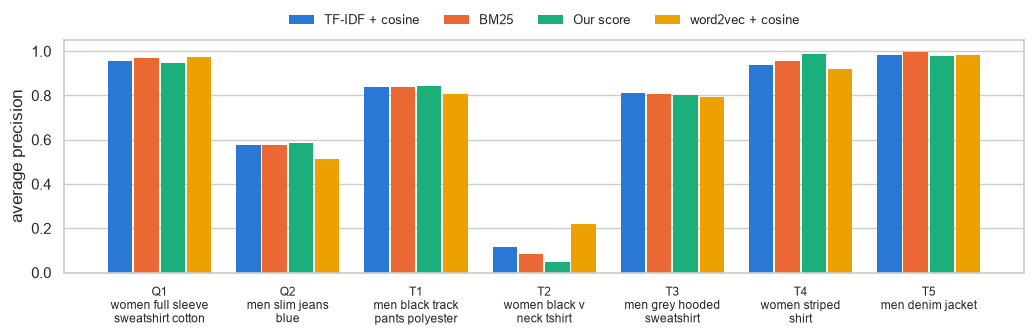

In [34]:
display(comparison[MAIN_COLS + ["test MRR"]].round(3))
display(comparison[AP_COLS].round(3))

# Figure 3: average precision of every query with the four methods
fig, ax = plt.subplots(figsize=(10.5, 3.6))
qs = list(QUERIES)
width = 0.19
for i, m in enumerate(METHODS):
    xs = np.arange(len(qs)) + (i - 1.5) * (width + 0.015)
    ax.bar(xs, [comparison.loc[NAMES[m], f"AP {q}"] for q in qs], width=width, color=COLORS[m], label=NAMES[m], linewidth=0)
import textwrap
ax.set(xticks=np.arange(len(qs)), xticklabels=[q + "\n" + textwrap.fill(QUERIES[q], 17) for q in qs],
       ylabel="average precision", ylim=(0, 1.05))
ax.tick_params(axis="x", labelsize=8.6)
ax.grid(axis="x", visible=False)
ax.legend(ncol=4, fontsize=9, loc="upper center", bbox_to_anchor=(0.5, 1.16), frameon=False)
savefig("average_precision_by_method")

In [35]:
# facts quoted in the report
def f(x):
    return None if x is None or (isinstance(x, float) and np.isnan(x)) else float(x)

summary = {
    "comparison": {m: {k: f(v) for k, v in comparison.loc[NAMES[m]].items()} for m in METHODS},
    "agreement_tfidf_bm25": {q: {k: f(v) for k, v in agree.loc[q].items()} for q in agree.index},
    "length_tf_effect": {q: {k: f(v) for k, v in effects.loc[q].items()} for q in effects.index},
    "offer_quality": {f"{k} | {m}": {c: f(v) for c, v in quality.loc[(k, m)].items()} for k, m in quality.index},
    "custom_params": custom.params.__dict__, "custom_mean_rating": custom.mean_rating,
    "word2vec": {"vocabulary": len(wv), "dimensions": int(wv.vector_size),
                 "pairs": {r["pair"]: f(r["cosine"]) for _, r in pair_sim.iterrows()}},
    "word2vec_stats": {q: {k: f(v) for k, v in w2v_stats.loc[q].items()} for q in w2v_stats.index},
    "representations": {name: {k: f(v) for k, v in rep_table.loc[name].items()} for name in rep_table.index},
    "q1_judged_documents": q1_judged, "t2_ratings": t2_facts,
}
with open(os.path.join(RES_DIR, "summary.json"), "w") as fh:
    json.dump(summary, fh, indent=1)
print("results written to", os.path.relpath(RES_DIR), "| figures written to", os.path.relpath(FIG_DIR))

results written to results | figures written to figures


1. **Pipeline.** Query → pre-processing of Part 1 → conjunctive retrieval of Part 2 → one of four rankings. The four return
   the same documents; only the order changes.
2. **TF-IDF vs BM25.** Both prefer short documents; the cosine more strongly (it normalises by every term of the document),
   while BM25 accepts a longer document that repeats the query terms. The first positions are often different near-duplicate
   products, but the MAP of the two is the same within one hundredth.
3. **Our score.** BM25 corrected by the match in the title, the rating, the discount and the stock. Relevance stays at the level
   of BM25 while the products in the first positions are better rated, more discounted and available.
4. **word2vec + cosine.** Top-20 lists for the five queries in `results/word2vec_top20.csv`. As a re-ranker of the AND results
   it is comparable to the lexical scores; without the AND it cannot keep the attributes of the query.
5. **Better representations.** Weighted averages and doc2vec do not improve the plain average here; see the report.